In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
!pip install snntorch
import snntorch as snn
from snntorch import surrogate
from torch.utils.data import DataLoader, TensorDataset, SubsetRandomSampler, RandomSampler, Dataset
import torch.optim as optim
from snntorch import functional as SF
from snntorch import utils
from sklearn.model_selection import StratifiedKFold
import seaborn as sns
import torchvision.transforms as T
from sklearn.model_selection import train_test_split
import torch.nn.functional as F
import time
from sklearn.metrics import confusion_matrix

Sane people: 1349
People with pneumonia: 3883
Class 0 in train set: 1079
Class 1 in train set: 3106
Class 0 in test set: 270
Class 1 in test set: 777


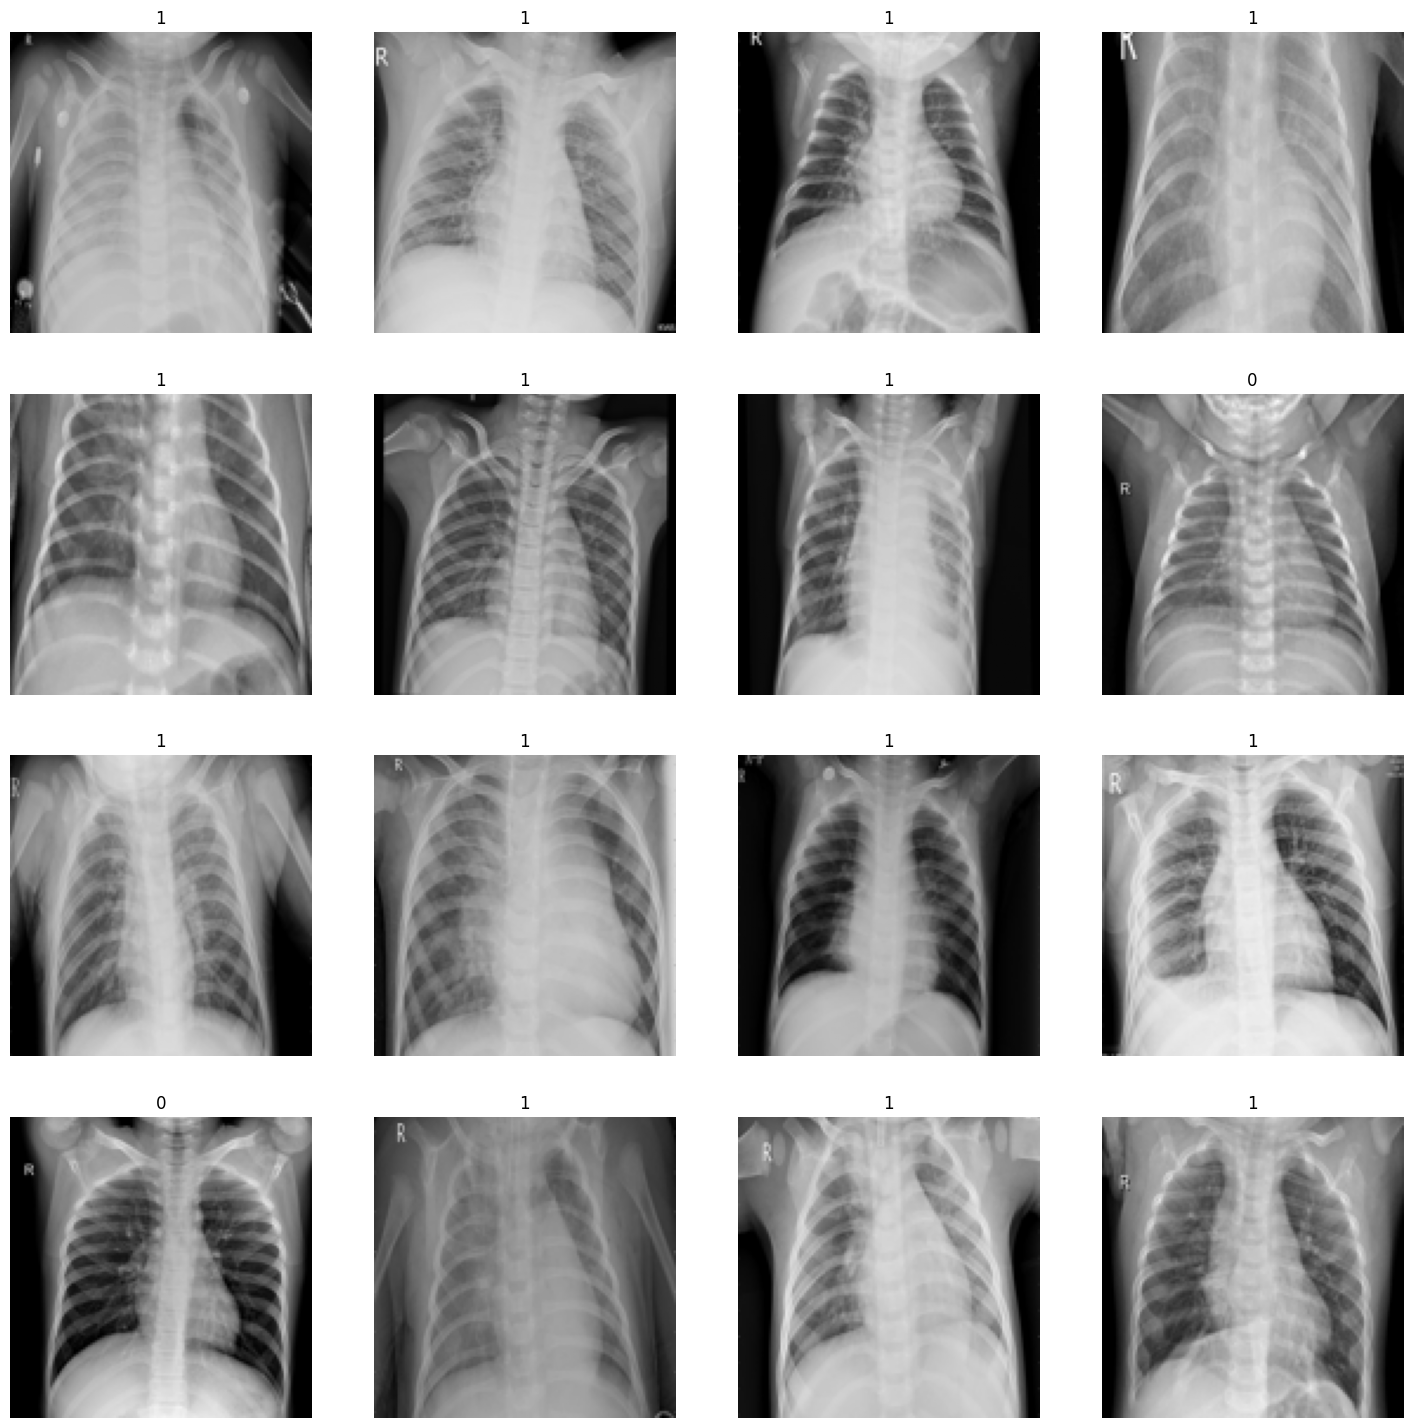

In [4]:
path = "/kaggle/input/datasets/desimoneemanuele/dataset/dataset.npz"
data = np.load(path)
X = data['X'] / 255.0
y = data['y']
X_sane = X[y == 0]
X_pneumonia = X[y == 1]
np.random.seed(23)
torch.manual_seed(23)
num_sane = len(X_sane)
num_pneumonia = len(X_pneumonia)
print(f"Sane people: {num_sane}")
print(f"People with pneumonia: {num_pneumonia}")

fig, axs = plt.subplots(4,4, figsize=(18,18))
axs = axs.flatten()
for i in range(16):
    axs[i].imshow(X[i].transpose(1,2,0))
    axs[i].set_title(y[i])
    axs[i].axis("off")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Class 0 in train set: {(y_train == 0).sum()}")
print(f"Class 1 in train set: {(y_train == 1).sum()}")
print(f"Class 0 in test set: {(y_test == 0).sum()}")
print(f"Class 1 in test set: {(y_test == 1).sum()}")

X_train = torch.tensor(X_train)
X_test = torch.tensor(X_test)
y_train = torch.tensor(y_train)
y_test_tensor = torch.tensor(y_test)

In [5]:
class Model(nn.Module):
    def __init__(self, beta=0.95, num_steps=25):
        super().__init__()

        self.spacialFeatureExtractionBlock = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.dim_output_cnn_flattened = 128*16*16 #dim output cnn flattened = 128*16*16

        self.num_steps = num_steps

        self.temporalDynamicsModellingBlock = nn.GRU(
            input_size= self.dim_output_cnn_flattened,
            hidden_size=256,
            num_layers=2,
            bidirectional=True,
            dropout=0.3
        )

        self.featureProjectionLinearBlock = nn.Sequential(
            nn.Linear(in_features=self.dim_output_cnn_flattened, out_features=128),
            nn.Linear(in_features=128, out_features=64),
            nn.Linear(in_features=64, out_features=256),
            nn.Sigmoid()
        )

        # self.linearExpansion = nn.Linear(in_features=64, out_features=256)

        self.beta = beta

        #SNN layers
        self.fclif1 = nn.Linear(in_features=512, out_features=512)
        self.lif1 = snn.Leaky(beta=self.beta, spike_grad=surrogate.fast_sigmoid())
        self.fclif2 = nn.Linear(in_features=768, out_features=768)
        self.lif2 = snn.Leaky(beta=self.beta, spike_grad=surrogate.fast_sigmoid())

        # 2*256 given by the two GRU outpus + 256 given by the linear projection output = 768 output SNN = input decision block
        self.decisionHeadBlock_input_dimension = 768

        self.decisionHeadBlock = nn.Sequential(
            nn.Linear(in_features=self.decisionHeadBlock_input_dimension, out_features=512),
            nn.LeakyReLU(0.1),
            nn.Dropout(p=0.4),
            nn.Linear(in_features=512, out_features=128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p=0.4),
            nn.Linear(in_features=128, out_features=2)
        )

    def forward(self, x):
        out_cnn = self.spacialFeatureExtractionBlock(x)
        out_cnn_flattened = nn.Flatten()(out_cnn)
        in_gru = out_cnn_flattened.repeat(self.num_steps, 1, 1)
        out_gru, _ = self.temporalDynamicsModellingBlock(in_gru)
        out_linear_projection = self.featureProjectionLinearBlock(out_cnn_flattened)
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        spk2_rec = []
        for step in range(self.num_steps):
             in_lif1 = self.fclif1(out_gru[step])
             spk1, mem1 = self.lif1(in_lif1, mem1)
             fused_input = torch.cat((spk1, out_linear_projection), dim=1)
             in_lif2 = self.fclif2(fused_input)
             spk2, mem2 = self.lif2(in_lif2, mem2)
             spk2_rec.append(spk2)
        spk2_rec = torch.stack(spk2_rec, dim=0)
        out_snn = torch.mean(spk2_rec, dim=0)
        out_decision_block = self.decisionHeadBlock(out_snn)
        return out_decision_block


class ModelWithoutGru(nn.Module):
    def __init__(self, beta=0.95, num_steps=25):
        super().__init__()

        self.spacialFeatureExtractionBlock = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.dim_output_cnn_flattened = 128*16*16 #dim output cnn flattened = 128*16*16

        self.num_steps = num_steps

        self.featureProjectionLinearBlock = nn.Sequential(
            nn.Linear(in_features=self.dim_output_cnn_flattened, out_features=128),
            nn.Linear(in_features=128, out_features=64)
        )

        self.beta = beta

        self.liffc = nn.Linear(in_features=64, out_features=256)

        #SNN layers
        self.lif1 = snn.Leaky(beta=self.beta, spike_grad=surrogate.fast_sigmoid())
        self.lif2 = snn.Leaky(beta=self.beta, spike_grad=surrogate.fast_sigmoid())

        #256 given by the SSN output
        self.decisionHeadBlock_input_dimension = 256

        self.decisionHeadBlock = nn.Sequential(
            nn.Linear(in_features=self.decisionHeadBlock_input_dimension, out_features=128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p=0.4),
            nn.Linear(in_features=128, out_features=64),
            nn.LeakyReLU(0.1),
            nn.Dropout(p=0.4),
            nn.Linear(in_features=64, out_features=2)
        )

    def forward(self, x):
        out_cnn = self.spacialFeatureExtractionBlock(x)
        out_cnn_flattened = nn.Flatten()(out_cnn)
        out_linear_projection = self.featureProjectionLinearBlock(out_cnn_flattened)
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        spk2_rec = []
        for step in range(self.num_steps):
             spk1, mem1 = self.lif1(out_linear_projection, mem1)
             spk1_linear = self.liffc(spk1)
             spk2, mem2 = self.lif2(spk1_linear, mem2)
             spk2_rec.append(spk2)
        spk2_rec = torch.stack(spk2_rec, dim=0)
        out_snn = torch.mean(spk2_rec, dim=0)
        out_decision_block = self.decisionHeadBlock(out_snn)
        return out_decision_block

In [6]:
def cross_validation(model, X_train, y_train, lr):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)
  print(f"Using: {device}")
  k_folds = 5
  epochs = 30
  batch_size = 32
  weight_decay = 1e-5

  #I split my training data in 5 folds for cross validation
  kfold = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

  #dictionaries to save the results
  training_loss_per_epoch = {}
  validation_loss_per_epoch = {}
  training_accuracy_cross_val = {}
  validation_accuracy_cross_val = {}

  print("--------------------------------")
  print(f"{k_folds}-Fold Cross Validation")
  print("--------------------------------")

  all_oof_preds = []
  all_oof_targets = []

  #val_ids: indexes of the current fold (for validation)
  #train_ids:all the other indexes (for training)
  for fold, (train_ids, val_ids) in enumerate(kfold.split(X_train,y_train)):
      print(f"\nFOLD {fold+1}/{k_folds}")
      print("--------------------------------")
      training_loss_per_epoch[fold] = []
      validation_loss_per_epoch[fold] = []
      training_accuracy_cross_val[fold] = []
      validation_accuracy_cross_val[fold] = []

      X_tr_fold = X_train[train_ids]
      y_tr_fold = y_train[train_ids]
      X_val_fold = X_train[val_ids]
      y_val_fold = y_train[val_ids]

      train_dataset = TensorDataset(X_tr_fold.float(), y_tr_fold.long())
      val_dataset = TensorDataset(X_val_fold.float(), y_val_fold.long())

      #the DataLoader ease the syntax required for the batches usage
      train_loader = DataLoader(train_dataset, batch_size=batch_size)
      val_loader = DataLoader(val_dataset, batch_size=batch_size)

      #new model of the current iteration of K-Fold Cross Validation (untrained of course)
      model = Model().to(device)

      #weight decay is a form of L2 regularization, it decreases the weights' values
      optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

      #the scheduler modifies the lr. In this case it starts from lr = max_lr and it then slowly decreases to very small values
      #steps_per_epoch = how many times the weights are updated per epoch(len(train_loader) is the number of batches)
      #this is needed because the scheduler can undarstand a priori how to reduce the weights for each epoch a priori
      #epochs = how long the scheduling lasts (during all training in this case)
      scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader), epochs=epochs)
      #I act on the loss function to address the imbalance of the dataset
      class_counts = torch.bincount(y_tr_fold.long())
      total_samples = len(y_tr_fold)
      num_classes = len(class_counts)
      class_weights = total_samples / (num_classes * class_counts.float())
      #this makes the model classify a pneumonia with more ease to make the model less conservative
      class_weights[1] *= 1.5
      class_weights = class_weights.to(device)
      criterion = nn.CrossEntropyLoss(weight=class_weights)

      for epoch in range(epochs):
          if epoch%5 == 0 or epoch == 29:
              print(f"Epoch {epoch}")
          #I set the model in training mode (Dropout and Batch Normalization activated)
          model.train()
          running_loss = 0.0
          correct = 0
          total = 0
          #I use the train loader to easily extract the batches
          for i, (images, labels) in enumerate(train_loader):
              images,labels = images.to(device), labels.to(device)
              #I reset the SNN memories (the membrane potentials of the previous batches)
              utils.reset(model)
              #the Pytorch framework accumulates the gradients of the previous batches, so I reset them
              optimizer.zero_grad()
              #I evaluate the model with the current parameters
              outputs = model(images)
              #I compute the loss with the current parameters
              loss = criterion(outputs, labels)
              #I compute the loss gradients wrt each parameter
              loss.backward()
              #I update the parameters of the NN through backpropagation
              optimizer.step()
              #I modify the learning rate of the next step through the scheduler I configured before
              scheduler.step()
              #I save the value of the current loss using .item() as a float
              running_loss += loss.item()
              # I compute the predictions
              _, predicted = torch.max(outputs.data, 1)
              total += labels.size(0)
              correct += (predicted == labels).sum().item()
          #the training loss for epoch k is the average among all batches because
          #recomputing it at the end on the whole dataset is too expensive
          #same goes for the accuracy
          training_loss_per_epoch[fold].append(running_loss/len(train_loader))
          training_accuracy_cross_val[fold].append(100*correct/total)
          
          # I set the model in evaluation mode (no dropout and batch normalization) to compute the validation metrics
          model.eval()
          correct_val = 0
          total_val = 0
          running_loss_val = 0
          #I don't memorize the gradients because I don't need to apply backpropagation
          with torch.no_grad():
              for images, labels in val_loader:
                  images, labels = images.to(device), labels.to(device)
                  utils.reset(model)
                  outputs = model(images)
                  _, predicted = torch.max(outputs.data, 1)
                  loss_val = criterion(outputs, labels)
                  running_loss_val += loss_val.item()
                  total_val += labels.size(0)
                  correct_val += (predicted == labels).sum().item()

          validation_loss_per_epoch[fold].append(running_loss_val/len(val_loader))
          acc_fold = 100 * correct_val / total_val
          validation_accuracy_cross_val[fold].append(acc_fold)

      # I evaluate the model at the end of the fold to later build a global confusion matrix
      model.eval()
      with torch.no_grad():
          for images, labels in val_loader:
              images,labels = images.to(device), labels.to(device)
              utils.reset(model)
              outputs = model(images)
              _, predicted = torch.max(outputs.data, 1)
              all_oof_preds.extend(predicted.cpu().numpy())
              all_oof_targets.extend(labels.cpu().numpy())

  global_cm = confusion_matrix(all_oof_targets, all_oof_preds)

  return training_loss_per_epoch, training_accuracy_cross_val, validation_loss_per_epoch, validation_accuracy_cross_val, global_cm

In [7]:
model = Model()
tr_loss_per_epoch = {} 
tr_acc_cross_val = {} 
val_loss_per_epoch = {} 
val_acc_cross_val = {}
global_cm = {}
lr_list = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
for lr in lr_list:
    print("--------------------------------")
    print(f"\nCross Validation for learning rate = {lr}\n")
    print("--------------------------------")
    tr_loss_per_epoch[lr], tr_acc_cross_val[lr], val_loss_per_epoch[lr], val_acc_cross_val[lr], global_cm[lr] = cross_validation(model, X_train, y_train, lr)

--------------------------------

Cross Validation for learning rate = 0.01

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 2/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 3/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 4/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 5/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29
--------------------------------

Cross Validation for learning rate = 0.001

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoc

In [8]:
def plot_xval_results(training_loss_per_epoch, training_accuracy_cross_val, validation_loss_per_epoch, validation_accuracy_cross_val):
    k_folds = 5
    matrix_temp = np.array([validation_accuracy_cross_val[f] for f in range(k_folds)])
    avg_validation_accuracy_cv = np.mean(matrix_temp, axis=0)
    matrix_temp = np.array([training_accuracy_cross_val[f] for f in range(k_folds)])
    avg_training_accuracy_cv = np.mean(matrix_temp, axis=0)
    matrix_temp = np.array([training_loss_per_epoch[f] for f in range(k_folds)])
    avg_training_loss = np.mean(matrix_temp, axis=0)
    matrix_temp = np.array([validation_loss_per_epoch[f] for f in range(k_folds)])
    avg_validation_loss = np.mean(matrix_temp, axis=0)
    plt.plot(avg_training_loss, label="train loss")
    plt.plot(avg_validation_loss, label="val loss")
    plt.legend()
    print(f"Training loss = {avg_training_loss[-1]}")
    print(f"Validation loss = {avg_validation_loss[-1]}")
    print(f"Training accuracy using Cross Validation = {avg_training_accuracy_cv[-1]:.2f}%")
    print(f"Validation accuracy using Cross Validation = {avg_validation_accuracy_cv[-1]:.2f}%")

Training loss = 0.00042722503366392277
Validation loss = 0.11295726970538791
Training accuracy using Cross Validation = 100.00%
Validation accuracy using Cross Validation = 97.75%


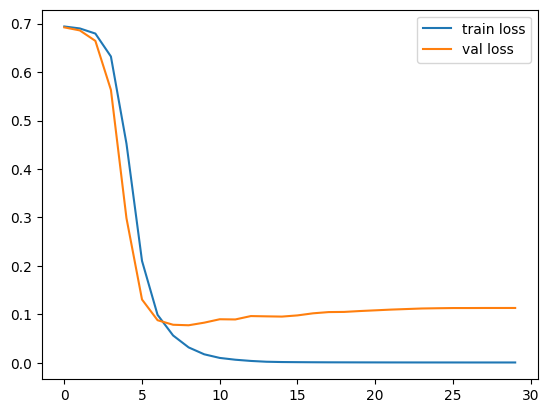

In [20]:
lr = 1e-5
plot_xval_results(tr_loss_per_epoch[lr], tr_acc_cross_val[lr], val_loss_per_epoch[lr], val_acc_cross_val[lr])

In [10]:
def show_confusion_matrix(cm):
    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]
    Recall = TP / (TP + FN)
    Precision = TP / (TP + FP)
    F1_Score = 2*(Precision*Recall) / (Precision + Recall)
    print(f"Recall = {Recall:.4f}")
    print(f"Precision = {Precision:.4f}")
    print(f"F1-Score = {F1_Score:.4f}")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'Pneumonia'],
                yticklabels=['Normal', 'Pneumonia'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

Recall = 0.9855
Precision = 0.9842
F1-Score = 0.9849


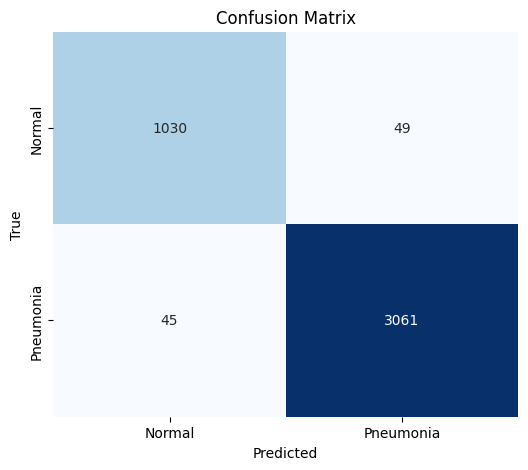

In [11]:
lr = 1e-5
show_confusion_matrix(global_cm[lr])

In [66]:
lr_list =  [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
avg = {}
print("Validation losses for different values of lr for the model")
for lr in lr_list:
    sum = 0
    print("------------------------")
    print(f"lr = {lr}:")
    print("------------------------")
    for fold in range(5):
        loss = val_loss_per_epoch[lr][fold][-1]
        sum += loss
        print(f"Loss for fold {fold+1} = {loss:.4f}")
    avg[lr] = sum/5
    print()
    print(f"Average loss = {avg[lr]:.4f}")
    print()

best_lr = min(avg, key=avg.get)
print("------------------------")
print()
print(f"The best lr is {best_lr}")

Validation losses for different values of lr for the model
------------------------
lr = 0.01:
------------------------
Loss for fold 1 = 0.2465
Loss for fold 2 = 0.1996
Loss for fold 3 = 0.2419
Loss for fold 4 = 0.1673
Loss for fold 5 = 0.6732

Average loss = 0.3057

------------------------
lr = 0.001:
------------------------
Loss for fold 1 = 0.0772
Loss for fold 2 = 0.1339
Loss for fold 3 = 0.1982
Loss for fold 4 = 0.2904
Loss for fold 5 = 0.1334

Average loss = 0.1666

------------------------
lr = 0.0001:
------------------------
Loss for fold 1 = 0.1348
Loss for fold 2 = 0.1125
Loss for fold 3 = 0.1283
Loss for fold 4 = 0.2076
Loss for fold 5 = 0.1030

Average loss = 0.1372

------------------------
lr = 1e-05:
------------------------
Loss for fold 1 = 0.1329
Loss for fold 2 = 0.0979
Loss for fold 3 = 0.1366
Loss for fold 4 = 0.1122
Loss for fold 5 = 0.0851

Average loss = 0.1130

------------------------
lr = 1e-06:
------------------------
Loss for fold 1 = 0.3010
Loss for f

In [12]:
model = ModelWithoutGru()
tr_loss_per_epoch_wout_gru = {} 
tr_acc_cross_val_wout_gru = {} 
val_loss_per_epoch_wout_gru = {} 
val_acc_cross_val_wout_gru = {}
global_cm_wout_gru = {}
lr_list = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
for lr in lr_list:
    print("--------------------------------")
    print(f"\nCross Validation for learning rate = {lr}\n")
    print("--------------------------------")
    tr_loss_per_epoch_wout_gru[lr], tr_acc_cross_val_wout_gru[lr], val_loss_per_epoch_wout_gru[lr], val_acc_cross_val_wout_gru[lr], global_cm_wout_gru[lr] = cross_validation(model, X_train, y_train, lr)

--------------------------------

Cross Validation for learning rate = 0.01

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 2/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 3/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 4/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 5/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29
--------------------------------

Cross Validation for learning rate = 0.001

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoc

Training loss = 0.00010740985738915956
Validation loss = 0.12732668552734377
Training accuracy using Cross Validation = 100.00%
Validation accuracy using Cross Validation = 98.14%


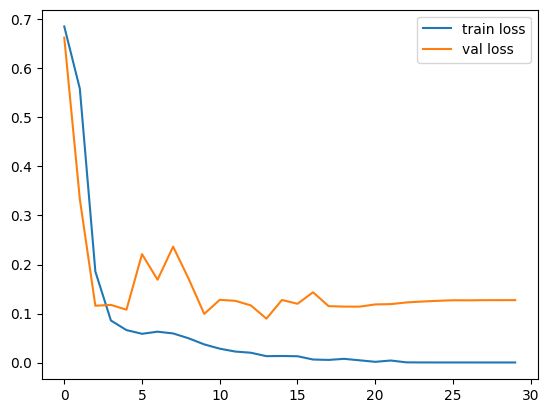

In [16]:
lr = 1e-4
plot_xval_results(tr_loss_per_epoch_wout_gru[lr], tr_acc_cross_val_wout_gru[lr], val_loss_per_epoch_wout_gru[lr], val_acc_cross_val_wout_gru[lr])

Recall = 0.9849
Precision = 0.9839
F1-Score = 0.9844


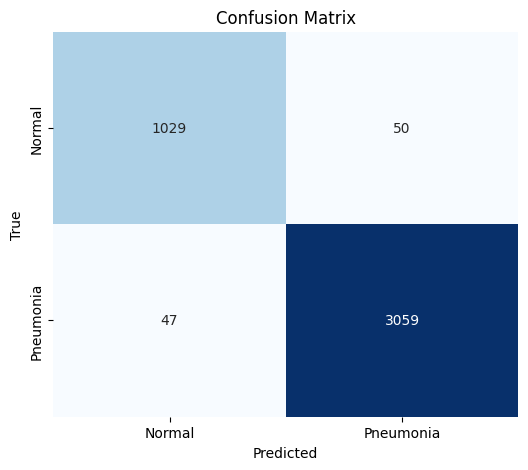

In [21]:
lr = 1e-5
show_confusion_matrix(global_cm_wout_gru[lr])

In [67]:
lr_list =  [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
avg_wout_gru = {}
print("Validation losses for different values of lr for the model without GRU")
for lr in lr_list:
    sum = 0
    print("------------------------")
    print(f"lr = {lr}:")
    print("------------------------")
    for fold in range(5):
        loss = val_loss_per_epoch_wout_gru[lr][fold][-1]
        sum += loss
        print(f"Loss for fold {fold+1} = {loss:.4f}")
    avg_wout_gru[lr] = sum/5
    print()
    print(f"Average loss = {avg_wout_gru[lr]:.4f}")
    print()

best_lr_wout_gru = min(avg_wout_gru, key=avg_wout_gru.get)
print("------------------------")
print()
print(f"The best lr is {best_lr_wout_gru}")

Validation losses for different values of lr for the model without GRU
------------------------
lr = 0.01:
------------------------
Loss for fold 1 = 0.2829
Loss for fold 2 = 0.1653
Loss for fold 3 = 0.6656
Loss for fold 4 = 0.2142
Loss for fold 5 = 0.6724

Average loss = 0.4001

------------------------
lr = 0.001:
------------------------
Loss for fold 1 = 0.1601
Loss for fold 2 = 0.1446
Loss for fold 3 = 0.1575
Loss for fold 4 = 0.2269
Loss for fold 5 = 0.1141

Average loss = 0.1606

------------------------
lr = 0.0001:
------------------------
Loss for fold 1 = 0.0945
Loss for fold 2 = 0.1131
Loss for fold 3 = 0.1326
Loss for fold 4 = 0.1831
Loss for fold 5 = 0.1134

Average loss = 0.1273

------------------------
lr = 1e-05:
------------------------
Loss for fold 1 = 0.0822
Loss for fold 2 = 0.1158
Loss for fold 3 = 0.1529
Loss for fold 4 = 0.1382
Loss for fold 5 = 0.1214

Average loss = 0.1221

------------------------
lr = 1e-06:
------------------------
Loss for fold 1 = 0.286

In [68]:
if avg[best_lr] < avg_wout_gru[best_lr_wout_gru]:
    print("The architecture with the BiGRU is better")
else:
    print("The architecture without the BiGRU is better")

The architecture with the BiGRU is better


In [22]:
#cross validation to choose the best beta (main parameter of the snn)
tr_loss_per_epoch_beta = {} 
tr_acc_cross_val_beta = {} 
val_loss_per_epoch_beta = {} 
val_acc_cross_val_beta = {}
global_cm_beta = {}
beta_list = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
#best lr found before
lr = 1e-5
for beta in beta_list:
    model = Model(beta=beta)
    print("--------------------------------")
    print(f"\nCross Validation for beta = {beta}\n")
    print("--------------------------------")
    tr_loss_per_epoch_beta[beta], tr_acc_cross_val_beta[beta], val_loss_per_epoch_beta[beta], val_acc_cross_val_beta[beta], global_cm_beta[beta] = cross_validation(model, X_train, y_train, lr)

--------------------------------

Cross Validation for beta = 0.5

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 2/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 3/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 4/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29

FOLD 5/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15
Epoch 20
Epoch 25
Epoch 29
--------------------------------

Cross Validation for beta = 0.7

--------------------------------
Using: cuda
--------------------------------
5-Fold Cross Validation
--------------------------------

FOLD 1/5
--------------------------------
Epoch 0
Epoch 5
Epoch 10
Epoch 15

Training loss = 0.0004295892588561401
Validation loss = 0.11273845292808901
Training accuracy using Cross Validation = 100.00%
Validation accuracy using Cross Validation = 97.85%


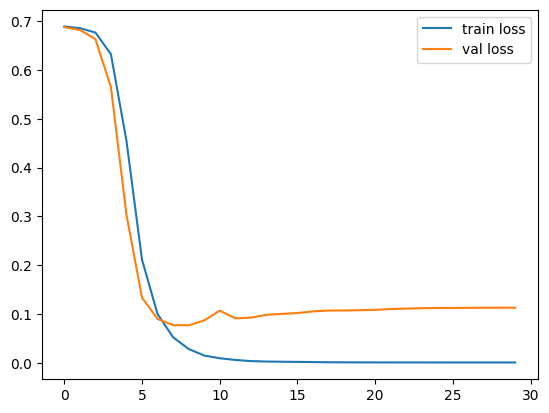

In [28]:
beta = 0.95
plot_xval_results(tr_loss_per_epoch_beta[beta], tr_acc_cross_val_beta[beta], val_loss_per_epoch_beta[beta], val_acc_cross_val_beta[beta])

In [54]:
beta_list = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
avg = {}
print("Validation losses for different values of beta")
for beta in beta_list:
    sum = 0
    print("------------------------")
    print(f"Beta = {beta}:")
    print("------------------------")
    for fold in range(5):
        loss = val_loss_per_epoch_beta[beta][fold][-1]
        sum += loss
        print(f"Loss for fold {fold+1} = {loss:.4f}")
    avg[beta] = sum/5
    print()
    print(f"Average loss = {avg[beta]:.4f}")
    print()

best_beta = min(avg, key=avg.get)
print("------------------------")
print()
print(f"The best beta is {best_beta}")

Validation losses for different values of beta
------------------------
Beta = 0.5:
------------------------
Loss for fold 1 = 0.1056
Loss for fold 2 = 0.1067
Loss for fold 3 = 0.1334
Loss for fold 4 = 0.1362
Loss for fold 5 = 0.1106

Average loss = 0.1185

------------------------
Beta = 0.7:
------------------------
Loss for fold 1 = 0.1500
Loss for fold 2 = 0.1128
Loss for fold 3 = 0.1377
Loss for fold 4 = 0.1292
Loss for fold 5 = 0.1034

Average loss = 0.1266

------------------------
Beta = 0.8:
------------------------
Loss for fold 1 = 0.1315
Loss for fold 2 = 0.1074
Loss for fold 3 = 0.1464
Loss for fold 4 = 0.1381
Loss for fold 5 = 0.1053

Average loss = 0.1257

------------------------
Beta = 0.9:
------------------------
Loss for fold 1 = 0.1086
Loss for fold 2 = 0.0975
Loss for fold 3 = 0.1375
Loss for fold 4 = 0.1487
Loss for fold 5 = 0.0940

Average loss = 0.1172

------------------------
Beta = 0.95:
------------------------
Loss for fold 1 = 0.1130
Loss for fold 2 = 0.0

In [30]:
def train(model, lr=1e-5):
    #here I train my model using all training data
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using: {device}")
    epochs = 30
    batch_size = 32
    weight_decay = 1e-5

    augmentation = T.Compose([
            T.RandomApply([
            T.Compose([
                T.RandomHorizontalFlip(p=0.5),
                T.RandomAffine(degrees=0, scale=(0.9, 1.1)),
                T.ColorJitter(brightness=0.2),
            ]),
        ], p=0.7),
    ])

    class AugmentedDataset(Dataset):
        def __init__(self, tensors):
            self.tensors = tensors
            self.transform = augmentation
    
        def __getitem__(self, index):
            x = self.tensors[0][index]
            y = self.tensors[1][index]
            x = self.transform(x)
            x = x.clamp(0.0, 1.0)
            return x, y
    
        def __len__(self):
            return self.tensors[0].size(0)
    
    dataset_train = AugmentedDataset((X_train.float(), y_train.long()))
    dataset_test = TensorDataset(X_test.float(), y_test_tensor.long())
    #historic data for plot purposes
    training_accuracy = []
    test_accuracy = []
    training_loss = []
    test_loss = []
    
    train_loader = DataLoader(dataset_train, batch_size=batch_size)
    test_loader = DataLoader(dataset_test, batch_size=batch_size)
    
    model = model.to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader), epochs=epochs)
    class_counts = torch.bincount(y_train.long())
    total_samples = len(y_train)
    num_classes = len(class_counts)
    class_weights = total_samples / (num_classes * class_counts.float())
    #this makes the model classify a pneumonia with more ease to make the model less conservative
    class_weights[1] *= 1.5
    class_weights = class_weights.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    
    for epoch in range(epochs):
        model.train()
        correct_train = 0
        total_train = 0
        running_loss_train = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images,labels = images.to(device), labels.to(device)
            utils.reset(model)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            running_loss_train += loss.item()
            optimizer.step()
            scheduler.step()
            _, predicted_train = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted_train == labels).sum().item()
        correct_test = 0
        total_test = 0
        running_loss_test = 0.0
        model.eval()
        for i, (images, labels) in enumerate(test_loader):
            images, labels = images.to(device), labels.to(device)
            with torch.no_grad():
                utils.reset(model)
                outputs_test = model(images)
                loss_test = criterion(outputs_test, labels)
                running_loss_test += loss_test.item()
            _, predicted_test = torch.max(outputs_test.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted_test == labels).sum().item()
        test_acc = 100*correct_test/total_test
        train_acc = 100*correct_train/total_train
        training_accuracy.append(train_acc)
        test_accuracy.append(test_acc)
        training_loss.append(running_loss_train/len(train_loader))
        test_loss.append(running_loss_test/len(test_loader))
    
        if epoch % 5 == 0 or epoch == 29:
            print(f"Training + Testing for epoch {epoch}")
            print(f"Training accuracy = {train_acc:.2f}%")
            print(f"Test accuracy = {test_acc:.2f}%")
            print()
    
    return training_accuracy, test_accuracy, training_loss, test_loss

In [31]:
model = Model(beta=0.95)
lr = 1e-5
training_accuracy, test_accuracy, training_loss, test_loss = train(model,lr)

Using: cuda
Training + Testing for epoch 0
Training accuracy = 73.60%
Test accuracy = 74.21%

Training + Testing for epoch 5
Training accuracy = 94.41%
Test accuracy = 95.51%

Training + Testing for epoch 10
Training accuracy = 97.04%
Test accuracy = 97.13%

Training + Testing for epoch 15
Training accuracy = 97.92%
Test accuracy = 97.52%

Training + Testing for epoch 20
Training accuracy = 98.33%
Test accuracy = 97.42%

Training + Testing for epoch 25
Training accuracy = 98.69%
Test accuracy = 97.71%

Training + Testing for epoch 29
Training accuracy = 98.95%
Test accuracy = 97.61%



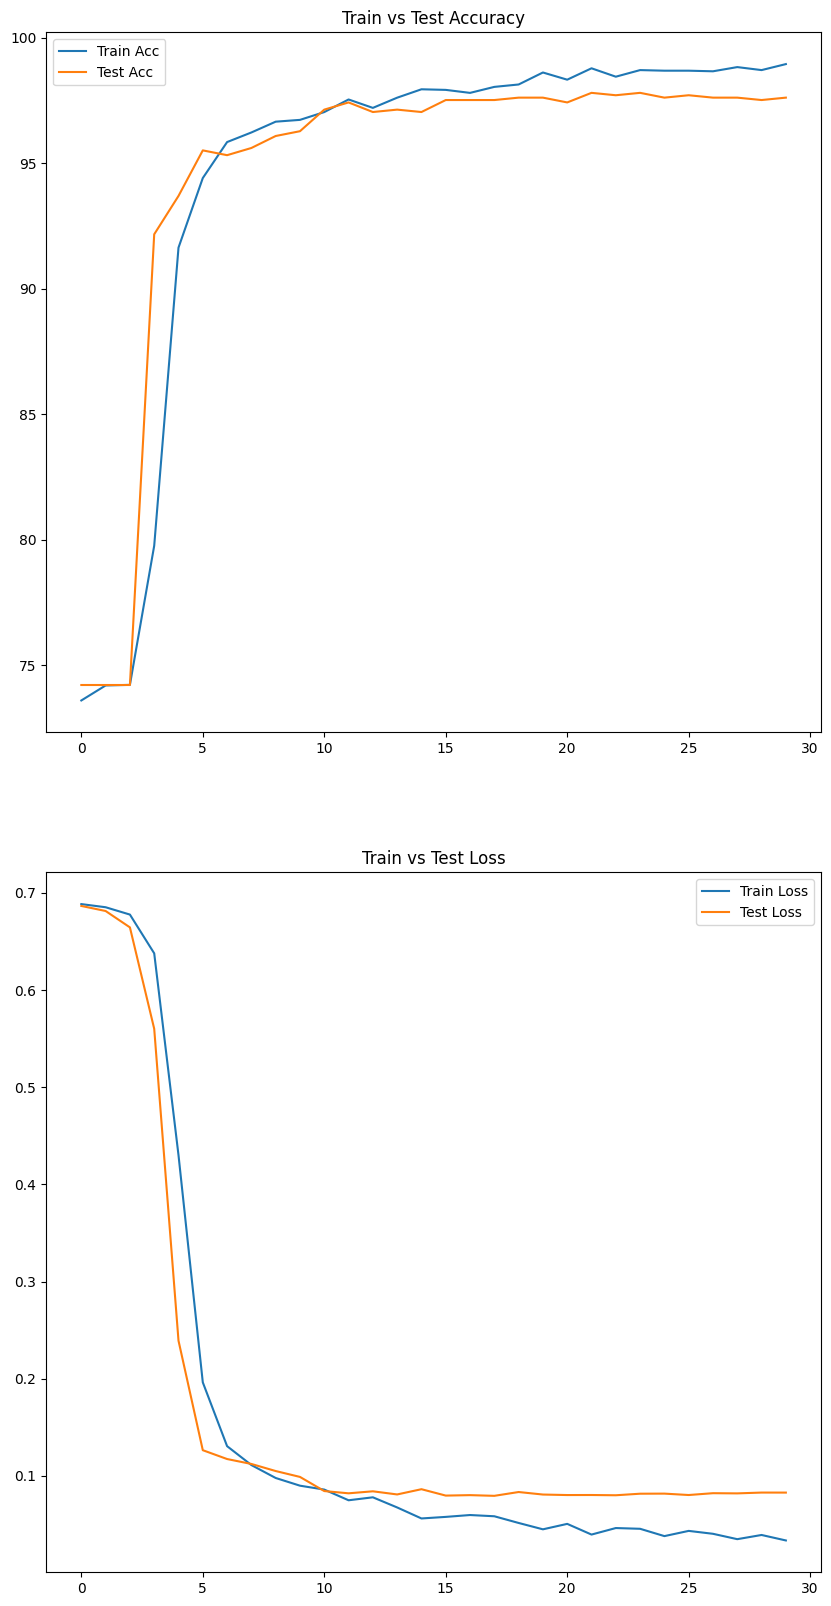

In [32]:
fig, axs = plt.subplots(2,1,figsize=(10,20))
axs = axs.flatten()
axs[0].plot(training_accuracy, label="Train Acc")
axs[0].plot(test_accuracy, label="Test Acc")
axs[0].set_title("Train vs Test Accuracy")
axs[0].legend()
axs[1].plot(training_loss, label="Train Loss")
axs[1].plot(test_loss, label="Test Loss")
axs[1].set_title("Train vs Test Loss")
axs[1].legend()
plt.savefig('/kaggle/working/train_vs_test.png', bbox_inches='tight')

In [33]:
def predict_images(model, images, device, batch_size=300):
    model.eval()
    predictions = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch_images = images[i : i + batch_size]
            batch_images = batch_images.float().to(device)
            utils.reset(model)
            outputs = model(batch_images)
            batch_preds = torch.argmax(outputs, dim=1)
            predictions.append(batch_preds.cpu().numpy())
    return np.concatenate(predictions)

Test loss = 0.08277 VS Training loss = 0.03350
Test accuracy = 97.61%
Recall = 0.9833
Precision = 0.9845
F1-Score = 0.9839


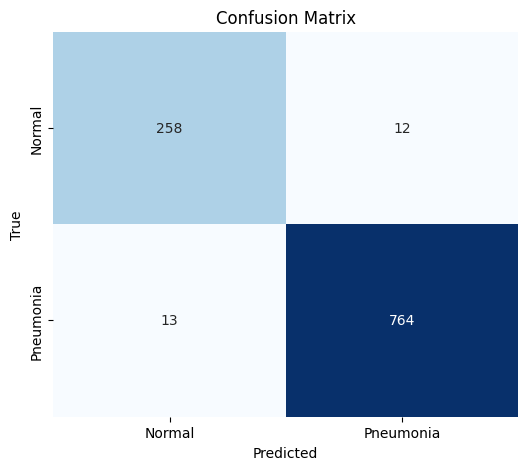

<Figure size 640x480 with 0 Axes>

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
preds = predict_images(model, X_test, device)
acc = np.mean(preds==y_test)
print(f"Test loss = {test_loss[-1]:.5f} VS Training loss = {training_loss[-1]:.5f}")
print(f"Test accuracy = {acc*100:.2f}%")
cm = confusion_matrix(y_test, preds)
show_confusion_matrix(cm)
plt.savefig('/kaggle/working/conf_matrix.png', bbox_inches='tight')

In [35]:
def blur_test(model):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    img_normal = X_test[y_test==0][0]
    img_pneumonia = X_test[y_test==1][0]
    sigma_values = [0.2, 0.4, 0.6]
    k_size = 41
    blurred_preds = {}
    fig, axs = plt.subplots(2,4,figsize=(16,8))
    axs[0,0].axis("off")
    axs[0,0].imshow(img_normal.permute(1, 2, 0))
    axs[0,0].set_title("Original Image")
    axs[1,0].axis("off")
    axs[1,0].imshow(img_pneumonia.permute(1, 2, 0))
    axs[1,0].set_title("Original Image")
    for i, s in enumerate(sigma_values):
        blurrer = T.GaussianBlur(kernel_size=k_size, sigma=s)
        blurred_normal = blurrer(img_normal)
        blurred_pneumonia = blurrer(img_pneumonia)
        blurred_normal_pred = predict_images(model, blurred_normal.unsqueeze(0), device, batch_size=1).item()
        blurred_pneumonia_pred = predict_images(model, blurred_pneumonia.unsqueeze(0), device, batch_size=1).item()
        axs[0,i+1].axis("off")
        axs[0,i+1].imshow(blurred_normal.permute(1, 2, 0))
        axs[0,i+1].set_title(f"pred = {blurred_normal_pred}, true label = 0 (sigma={s})")
        axs[1,i+1].axis("off")
        axs[1,i+1].imshow(blurred_pneumonia.permute(1, 2, 0))
        axs[1,i+1].set_title(f"pred = {blurred_pneumonia_pred}, true label = 1 (sigma={s})")

        #now I do it for all images
        blurred_test_set = torch.zeros_like(X_test)
        for j in range(len(X_test)):
            blurred_test_set[j] = blurrer(X_test[j])
        blurred_preds[s] = predict_images(model, blurred_test_set, device)
    return blurred_preds


def salt_pepper(img,p):
    noisy = img.clone()
    random_tensor = torch.rand_like(img.float())
    noisy[random_tensor < (p/2)] = 0
    noisy[random_tensor > (1-(p/2))] = 1.0
    return noisy


def salt_pepper_test(model):
    np.random.seed(123)
    p_values = [0.01, 0.05, 0.1]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    img_normal = X_test[y_test==0][0]
    img_pneumonia = X_test[y_test==1][0]
    noisy_preds = {}
    fig, axs = plt.subplots(2,4,figsize=(16,8))
    axs[0,0].axis("off")
    axs[0,0].imshow(img_normal.permute(1, 2, 0))
    axs[0,0].set_title("Original Image")
    axs[1,0].axis("off")
    axs[1,0].imshow(img_pneumonia.permute(1, 2, 0))
    axs[1,0].set_title("Original Image")
    for i, p in enumerate(p_values):
        salt_pepper_normal = salt_pepper(img_normal,p)
        salt_pepper_pneumonia = salt_pepper(img_pneumonia,p)
        salt_pepper_normal_pred = predict_images(model, salt_pepper_normal.unsqueeze(0), device, batch_size=1).item()
        salt_pepper_pneumonia_pred = predict_images(model, salt_pepper_pneumonia.unsqueeze(0), device, batch_size=1).item()
        axs[0,i+1].axis("off")
        axs[0,i+1].imshow(salt_pepper_normal.permute(1, 2, 0))
        axs[0,i+1].set_title(f"pred = {salt_pepper_normal_pred}, true label = 0 (p={p})")
        axs[1,i+1].axis("off")
        axs[1,i+1].imshow(salt_pepper_pneumonia.permute(1, 2, 0))
        axs[1,i+1].set_title(f"pred = {salt_pepper_pneumonia_pred}, true label = 1 (p={p})")

        noisy_test_set = torch.zeros_like(X_test)
        for j in range(len(X_test)):
            noisy_test_set[j] = salt_pepper(X_test[j], p)
        noisy_preds[p] = predict_images(model, noisy_test_set, device)
    return noisy_preds
    
def speckle(img,sigma):
    noisy = img.clone().float()
    noise = torch.randn_like(noisy) * sigma
    noisy = noisy + (noisy * noise)
    return noisy.clip(0,1.0)

def speckle_test(model):
    noisy_preds = {}
    np.random.seed(123)
    sigma_values = [0.1, 0.2, 0.3]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    img_normal = X_test[y_test==0][0]
    img_pneumonia = X_test[y_test==1][0]
    fig, axs = plt.subplots(2,4,figsize=(16,8))
    axs[0,0].axis("off")
    axs[0,0].imshow(img_normal.permute(1, 2, 0))
    axs[0,0].set_title("Original Image")
    axs[1,0].axis("off")
    axs[1,0].imshow(img_pneumonia.permute(1, 2, 0))
    axs[1,0].set_title("Original Image")
    for i, sigma in enumerate(sigma_values):
        speckle_normal = speckle(img_normal,sigma)
        speckle_pneumonia = speckle(img_pneumonia,sigma)
        speckle_normal_pred = predict_images(model, speckle_normal.unsqueeze(0), device, batch_size=1).item()
        speckle_pneumonia_pred = predict_images(model, speckle_pneumonia.unsqueeze(0), device, batch_size=1).item()
        axs[0,i+1].axis("off")
        axs[0,i+1].imshow(speckle_normal.permute(1, 2, 0))
        axs[0,i+1].set_title(f"pred = {speckle_normal_pred}, true label = 0 (sigma={sigma})")
        axs[1,i+1].axis("off")
        axs[1,i+1].imshow(speckle_pneumonia.permute(1, 2, 0))
        axs[1,i+1].set_title(f"pred = {speckle_pneumonia_pred}, true label = 1 (sigma={sigma})")
        
        noisy_test_set = torch.zeros_like(X_test)
        for j in range(len(X_test)):
            noisy_test_set[j] = speckle(X_test[j], sigma)
        noisy_preds[sigma] = predict_images(model, noisy_test_set, device)
    return noisy_preds

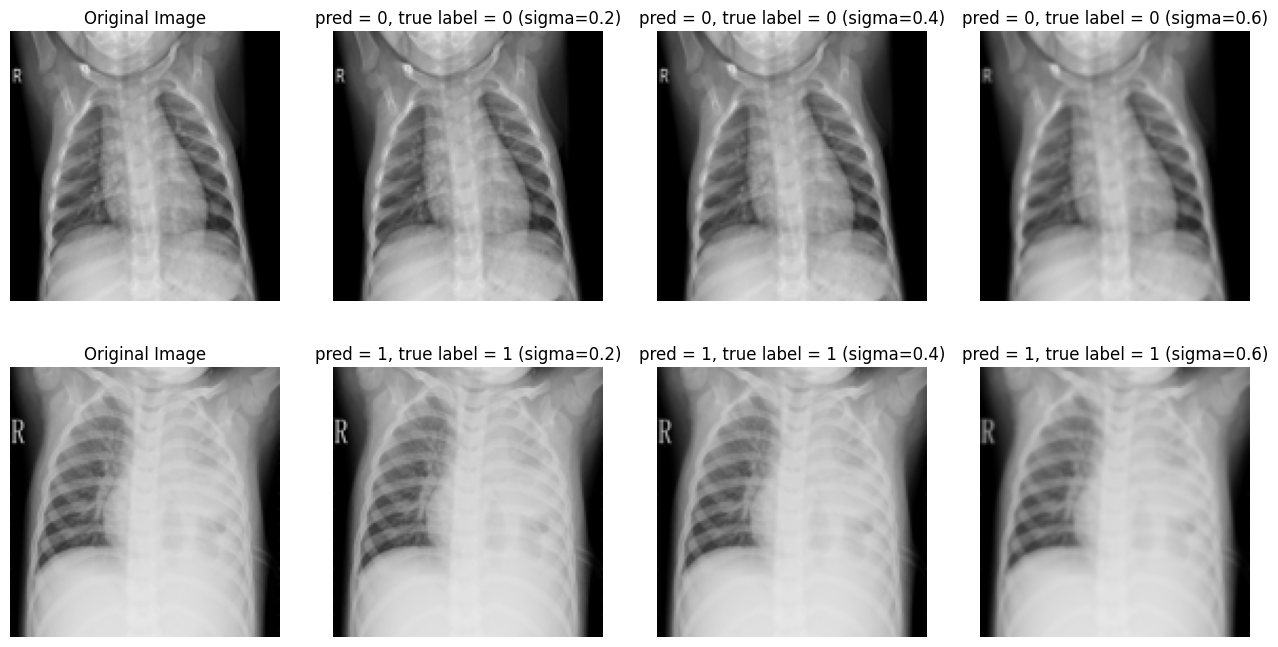

In [37]:
blurred_preds = blur_test(model)
plt.savefig('/kaggle/working/blur.png', bbox_inches='tight')

In [38]:
print("Discrepancies between predictions and blurred predictions")
for sigma in [0.2, 0.4, 0.6]:
    misspreds = np.sum(blurred_preds[sigma] != preds)
    print(f"sigma = {sigma} -> {misspreds} so the {100*misspreds/len(X_test):.2f}%")

Discrepancies between predictions and blurred predictions
sigma = 0.2 -> 0 so the 0.00%
sigma = 0.4 -> 0 so the 0.00%
sigma = 0.6 -> 13 so the 1.24%


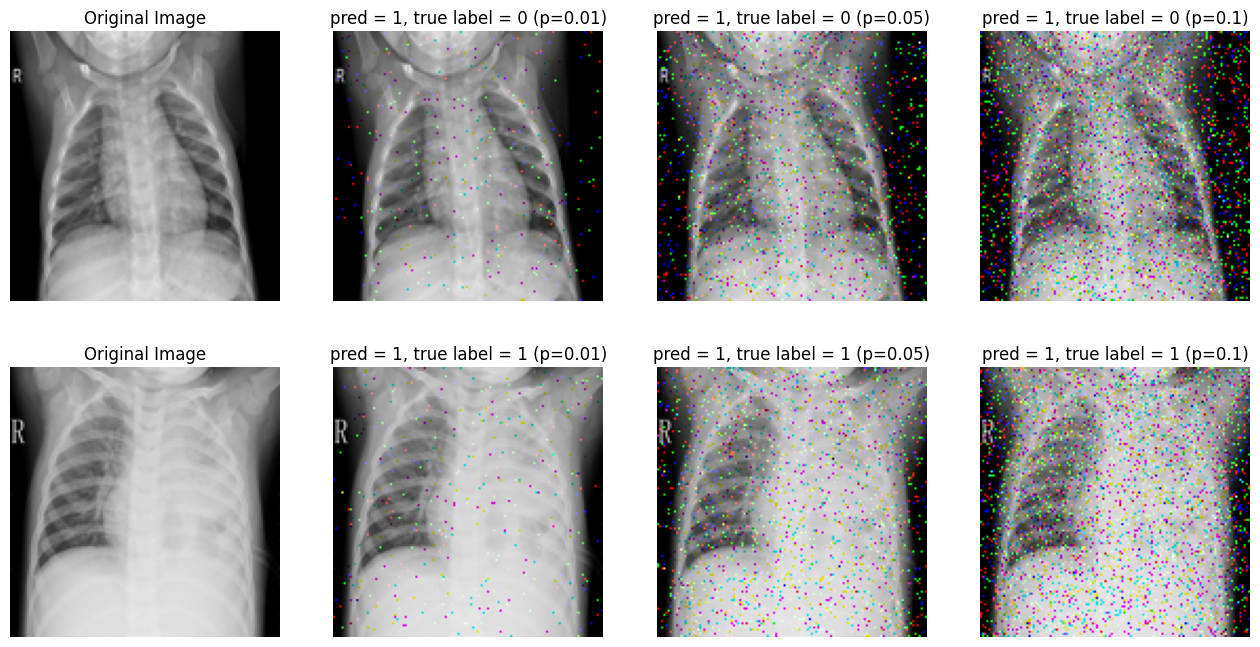

In [39]:
salt_pepper_preds = salt_pepper_test(model)
plt.savefig('/kaggle/working/salt_pepper.png', bbox_inches='tight')

In [40]:
print("Discrepancies between predictions and predictions with salt and pepper noise")
for p in [0.01, 0.05, 0.1]:
    misspreds = np.sum(salt_pepper_preds[p] != preds)
    print(f"sigma = {p} -> {misspreds} so the {100*misspreds/len(X_test):.2f}%")

Discrepancies between predictions and predictions with salt and pepper noise
sigma = 0.01 -> 184 so the 17.57%
sigma = 0.05 -> 270 so the 25.79%
sigma = 0.1 -> 271 so the 25.88%


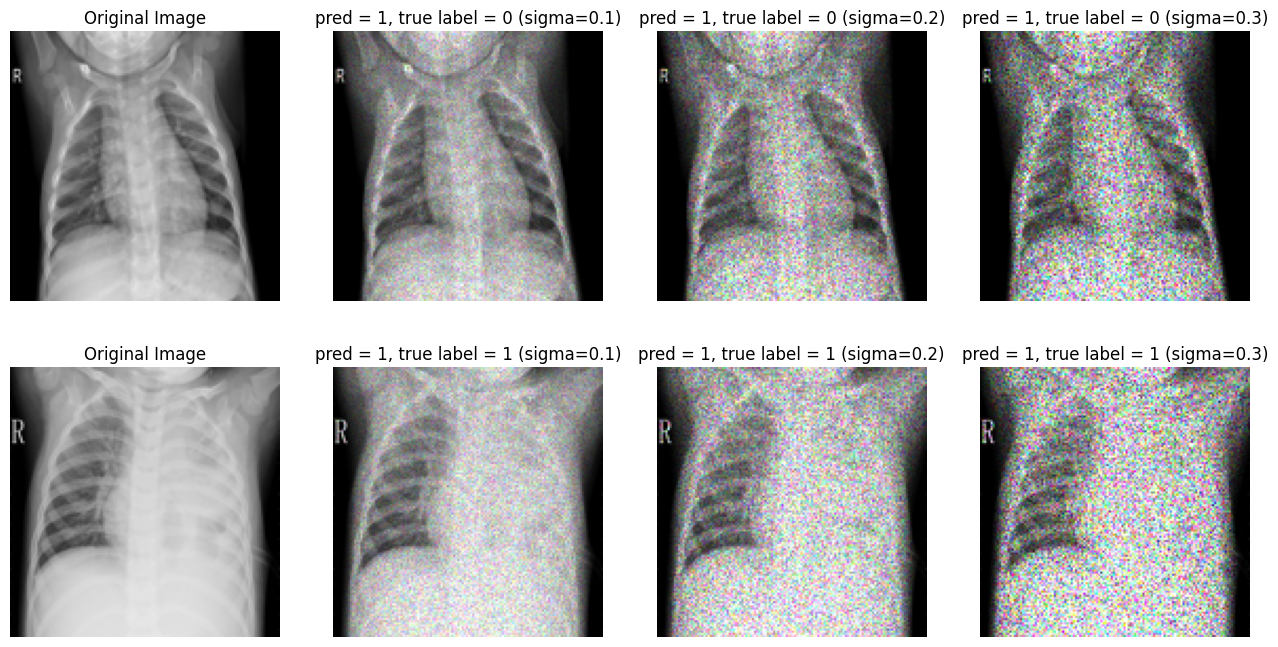

In [41]:
speckle_preds = speckle_test(model)
plt.savefig('/kaggle/working/speckle.png', bbox_inches='tight')

In [42]:
print("Discrepancies between predictions and predictions with speckle noise")
for sigma in [0.1, 0.2, 0.3]:
    misspreds = np.sum(speckle_preds[sigma] != preds)
    print(f"sigma = {sigma} -> {misspreds} so the {100*misspreds/len(X_test):.2f}%")

Discrepancies between predictions and predictions with speckle noise
sigma = 0.1 -> 118 so the 11.27%
sigma = 0.2 -> 270 so the 25.79%
sigma = 0.3 -> 291 so the 27.79%


In [72]:
#here I save my model
model_path = "model.pth"
torch.save(model.state_dict(), model_path)
print("Model saved")

Model saved


In [73]:
from IPython.display import FileLink
FileLink(r'model.pth')

/kaggle/working/model.pth